### The setup is similar to Battery_Degrad_PINN_0 notebook.

### Now we use capacity-loss data from lithium-ion cells stored at four temperatures: 15°C, 25°C, 35°C, and 45°C instead of just one.

### Source

The experimental data was extracted from:

> Naumann, M. et al., *Analysis and Modeling of Calendar Aging of a Commercial LiFePO₄/Graphite Cell*, Journal of The Electrochemical Society.

📄 **Paper:**  
https://iopscience.iop.org/article/10.1149/2.1181714jes

##**Experimental Setup**

In [ ]:
import torch
import torch.nn as nn
import numpy as np
import torch.nn.functional as F
import matplotlib.pyplot as plt

# 1. Experimental Data
time_days = [0, 7, 18, 32, 51, 73, 103, 121, 154, 196, 235]
t_data = torch.tensor(time_days, dtype=torch.float32).unsqueeze(1)

# Capacity Loss data at different temperatures
loss_15C = [0.000, 0.030, 0.040, 0.051, 0.062, 0.067, 0.085, 0.088, 0.089, 0.105, 0.112]
loss_25C = [0.000, 0.038, 0.050, 0.063, 0.077, 0.086, 0.103, 0.112, 0.108, 0.130, 0.139]
loss_35C = [0.000, 0.043, 0.063, 0.080, 0.097, 0.113, 0.127, 0.140, 0.153, 0.165, 0.178]
loss_45C = [0.000, 0.054, 0.078, 0.099, 0.128, 0.150, 0.176, 0.188, 0.209, 0.226, 0.244]

# Convert to Capacity Remaining (Q = 1 - Loss)
def to_q_tensor(loss_list):
    return 1.0 - torch.tensor(loss_list, dtype=torch.float32).unsqueeze(1)

q_true = [
    to_q_tensor(loss_15C),
    to_q_tensor(loss_25C),
    to_q_tensor(loss_35C),
    to_q_tensor(loss_45C)
]

##**Plotting the Raw Data**

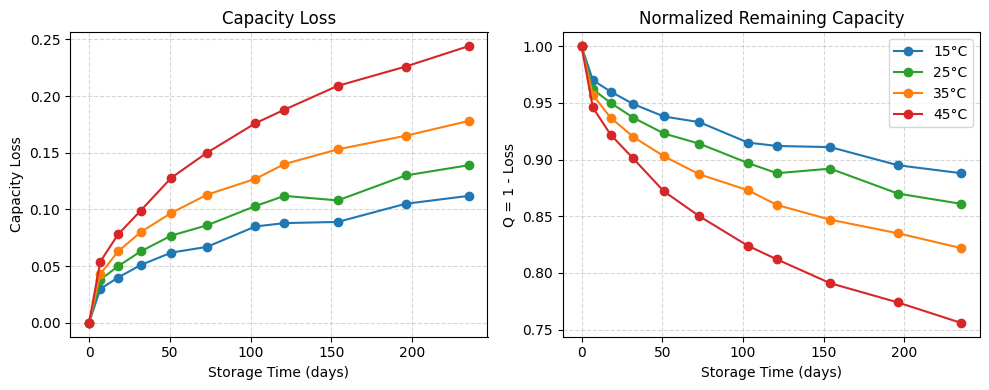

In [ ]:

loss_data = [loss_15C, loss_25C, loss_35C, loss_45C]
colors = ["tab:blue", "tab:green", "tab:orange", "tab:red"]
labels = ["15°C", "25°C", "35°C", "45°C"]

fig, ax = plt.subplots(1, 2, figsize=(10,4))

for loss, q, c, lbl in zip(loss_data, q_true, colors, labels):

    # Capacity loss
    ax[0].plot(time_days, loss, "o-", color=c, label=lbl)

    # Remaining capacity
    ax[1].plot(time_days,
               q.numpy().flatten(),
               "o-", color=c, label=lbl)

ax[0].set_title("Capacity Loss")
ax[0].set_xlabel("Storage Time (days)")
ax[0].set_ylabel("Capacity Loss")
ax[0].grid(True, ls="--", alpha=0.5)

ax[1].set_title("Normalized Remaining Capacity")
ax[1].set_xlabel("Storage Time (days)")
ax[1].set_ylabel("Q = 1 - Loss")
ax[1].grid(True, ls="--", alpha=0.5)

ax[1].legend()
plt.tight_layout()
plt.show()

###**Defining the PINN Architechture**



In [ ]:
class BatteryPINN(nn.Module):
    def __init__(self):
        super().__init__()

        # 1 input (time) -> 4 outputs (Q at 15°C, 25°C, 35°C, and 45°C)
        self.t_max = 235.0
        self.net = nn.Sequential(
            nn.Linear(1, 32), nn.Tanh(),
            nn.Linear(32, 32), nn.Tanh(),
            nn.Linear(32, 4)
        )

        # PINN: learn SEI and linear-aging rates for each temperature
        self.k_raw = nn.Parameter(torch.full((4,), -5.3))
        self.b_raw = nn.Parameter(torch.full((4,), -9.0))

    @property
    def k(self):
        return F.softplus(self.k_raw)  # Positive SEI rates

    @property
    def b(self):
        return F.softplus(self.b_raw)  # Positive linear-ageing rates

    def forward(self, t):
        return self.net(t / self.t_max)

##<h3>PINN Architechture</h3>

<div style="font-size: 16px;
border-left: 5px solid #2e86de;
padding: 12px 18px;
background-color: #f8f9fa;
border-radius: 4px;
">

The PINN takes storage time as input and predicts  remaining battery capacity for four storage temperatures (15°C, 25°C, 35°C, and 45°C).

**Diffusion Limited SEI Growth**:
$\Large \sqrt{t} \frac{dQ}{dt}+k+b\sqrt{t}=0$

The model treats **SEI degradation rate (k)** and **calendar-aging rate (b)** as trainable parameters too.
( In the end, an Arrhenius analysis is performed to investigate whether **k** follows expected degradation behaviour.)

The `softplus` transformation ensures that all learned degradation rates remain physically meaningful (positive).

###**Loss Function Formulation**

In [ ]:
def pinn_loss(model, t_data, q_true, t_phys,
              lambda_data=1, lambda_phys=10, lambda_ic=10):

    mse = nn.MSELoss()

    # Data loss
    q_data = model(t_data)
    loss_data = sum(
        mse(q_data[:, i:i+1], q_true[i])
        for i in range(4)
    )

    # Physics loss: sqrt(t)dQ/dt + k + b*sqrt(t) = 0
    q_phys = model(t_phys)
    sqrt_t = torch.sqrt(t_phys)
    loss_phys = 0.0

    for i in range(4):
        dQ_dt = torch.autograd.grad(
            q_phys[:, i:i+1], t_phys,
            grad_outputs=torch.ones_like(q_phys[:, i:i+1]),
            create_graph=True,
            retain_graph=True
        )[0]

        residual = (
            sqrt_t * dQ_dt +
            model.k[i] +
            model.b[i] * sqrt_t
        )

        loss_phys += torch.mean(residual**2)

    # Initial condition: Q(0) = 1
    t0 = torch.zeros((1, 1), device=t_data.device)
    loss_ic = mse(model(t0), torch.ones((1, 4), device=t_data.device))

    # Total loss
    loss_total = (
        lambda_data * loss_data +
        lambda_phys * loss_phys +
        lambda_ic * loss_ic
    )

    return loss_total, loss_data, loss_phys, loss_ic

<h3>PINN Loss Function</h3>

<div style="font-size: 16px;
border-left: 5px solid #2e86de;
padding: 12px 18px;
background-color: #f8f9fa;
border-radius: 4px;
">


$$
\large
L_{\text{Total}}
=
\lambda_{\text{Data}} L_{\text{Data}}
+
\lambda_{\text{Physics}} L_{\text{Physics}}
+
\lambda_{\text{IC}} L_{\text{IC}}
$$

where

$$
L_{\text{Data}}
=
\mathrm{MSE}
\left(
Q_{\text{NN}},
Q_{\text{Data}}
\right)
$$

ensures agreement with the experimental measurements,

$$
L_{\text{Physics}}
=
\mathrm{MSE}
\left(
\sqrt{t}\frac{dQ_{\text{NN}}}{dt}
+
k
+
b\sqrt{t}
\right)
$$

enforces the governing battery-degradation physics, and

$$
L_{\text{IC}}
=
\mathrm{MSE}
\left(
Q_{\text{NN}}(0),
1
\right)
$$

ensures that the battery starts from its known initial condition.

For this study,

$$
\lambda_{\text{Data}} = 1,
\qquad
\lambda_{\text{Physics}} = 10,
\qquad
\lambda_{\text{IC}} = 10
$$



By minimizing the total loss, the PINN learns the degradation trajectory while simultaneously identifying the unknown SEI-growth parameter \(k\) and the linear-ageing parameter \(b\) directly from sparse experimental observations.

---

The PINN is trained using both experimental measurements and physics collocation points(50 points) distributed across the storage-time domain.

Separate learning rates are used for the neural-network weights and the physical parameters (\(k\) and \(b\)), allowing the degradation parameters to converge efficiently.

###**Model Setup and Collocation points**

In [ ]:
model = BatteryPINN()

# Physics points exclude t = 0; Q(0) = 1 is enforced through the IC loss
t_phys = torch.linspace(0.1, 235.0, 60).unsqueeze(1).requires_grad_(True)

# Separate learning rates for network and physical parameters
lr_network = 1e-3
lr_physics = 3e-3

optimizer = torch.optim.Adam([
    {"params": model.net.parameters(), "lr": lr_network},
    {"params": [model.k_raw, model.b_raw], "lr": lr_physics}
])

### **Model Training**

In [ ]:
epochs = 15000

# Reset model and optimizer with the correct physical architecture
model = BatteryPINN()
optimizer = torch.optim.Adam([
    {"params": model.net.parameters(), "lr": lr_network},
    {"params": [model.k_raw, model.b_raw], "lr": lr_physics}
])

loss_history = []
data_loss_history = []
physics_loss_history = []
ic_loss_history = []

for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()

    # Enforce stronger physical constraints
    total_loss, data_loss, physics_loss, ic_loss = pinn_loss(
        model, t_data, q_true, t_phys,
        lambda_data=1.0,
        lambda_phys=10.0,
        lambda_ic=10.0
    )

    total_loss.backward()
    optimizer.step()

    loss_history.append(total_loss.item())
    data_loss_history.append(data_loss.item())
    physics_loss_history.append(physics_loss.item())
    ic_loss_history.append(ic_loss.item())

    if epoch % 3000 == 0:
        k_values = model.k.detach().cpu().numpy()
        b_values = model.b.detach().cpu().numpy()

        print(
            f"Epoch {epoch:05d} | Total: {total_loss.item():.6f} | "
            f"Data: {data_loss.item():.6f} | Physics: {physics_loss.item():.6f} | "
            f"IC: {ic_loss.item():.6f}"
        )
        for temp, k, b in zip([15, 25, 35, 45], k_values, b_values):
            print(f"  {temp}°C | k = {k:.7f} | b = {b:.7f}")

Epoch 00000 | Total: 14.742593 | Data: 3.682913 | Physics: 0.000296 | IC: 1.105672
  15°C | k = 0.0049941 | b = 0.0001238
  25°C | k = 0.0049643 | b = 0.0001230
  35°C | k = 0.0049643 | b = 0.0001230
  45°C | k = 0.0049643 | b = 0.0001230
Epoch 03000 | Total: 0.000676 | Data: 0.000488 | Physics: 0.000016 | IC: 0.000003
  15°C | k = 0.0028718 | b = 0.0000617
  25°C | k = 0.0033583 | b = 0.0000881
  35°C | k = 0.0047570 | b = 0.0000742
  45°C | k = 0.0071321 | b = 0.0000687
Epoch 06000 | Total: 0.000169 | Data: 0.000102 | Physics: 0.000007 | IC: 0.000000
  15°C | k = 0.0031757 | b = 0.0000226
  25°C | k = 0.0040545 | b = 0.0000227
  35°C | k = 0.0053780 | b = 0.0000217
  45°C | k = 0.0074869 | b = 0.0000233
Epoch 09000 | Total: 0.000080 | Data: 0.000041 | Physics: 0.000004 | IC: 0.000000
  15°C | k = 0.0032413 | b = 0.0000062
  25°C | k = 0.0040299 | b = 0.0000077
  35°C | k = 0.0052610 | b = 0.0000066
  45°C | k = 0.0074877 | b = 0.0000059
Epoch 12000 | Total: 0.000135 | Data: 0.000045 

In [ ]:

k_final = model.k.detach().cpu().numpy()
b_final = model.b.detach().cpu().numpy()

print("\n" + "=" * 62 + "\nFINAL DISCOVERED DEGRADATION PARAMETERS\n" + "=" * 62)
print(f"{'Temp':<10} {'k (SEI rate)':<16} {'b (linear)':<16}\n" + "-" * 62)

for i, temp in enumerate([15, 25, 35, 45]):
    print(f"{temp:2d} deg C    {k_final[i]:<16.7f} {b_final[i]:<16.7f}")

print("=" * 62)


FINAL DISCOVERED DEGRADATION PARAMETERS
Temp       k (SEI rate)     b (linear)      
--------------------------------------------------------------
15 deg C    0.0032717        0.0000005       
25 deg C    0.0040229        0.0000005       
35 deg C    0.0052661        0.0000004       
45 deg C    0.0074771        0.0000004       


**Quick Disclaimer:** Infereing unknown parameters using PINN technically constitutes an inverse PINN problem. But  here, I prefer the word PINN for simplicity.

<h3>PINN Physics Paramerters</h3>

<div style="font-size: 16px;
border-left: 5px solid #2e86de;
padding: 12px 18px;
background-color: #f8f9fa;
border-radius: 4px;
">
    
These are the physical parameters we are interested in.

In [ ]:
model.eval()

t_plot = torch.linspace(0, 235, 300).unsqueeze(1)

with torch.no_grad():
    q_pred_plot = model(t_plot)

t_data_np = t_data.cpu().numpy().flatten()
t_plot_np = t_plot.cpu().numpy().flatten()
q_pred_plot_np = q_pred_plot.cpu().numpy()

colors = ["tab:blue", "tab:green", "tab:orange", "tab:red"]
labels = ["15°C", "25°C", "35°C", "45°C"]


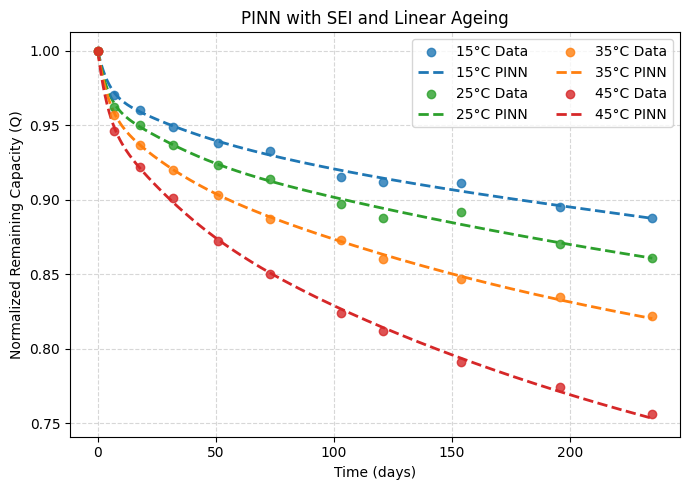

Temperature,R²,RMSE
15°C,0.99366,0.002583
25°C,0.99221,0.003535
35°C,0.99914,0.001536
45°C,0.99911,0.002191


In [ ]:
# Plot capacity predictions
plt.figure(figsize=(7, 5))

for i in range(4):
    plt.scatter(
        t_data_np,
        q_true[i].cpu().numpy().flatten(),
        color=colors[i],
        alpha=0.8,
        zorder=3,
        label=f"{labels[i]} Data"
    )

    plt.plot(
        t_plot_np,
        q_pred_plot_np[:, i],
        "--",
        color=colors[i],
        linewidth=2,
        label=f"{labels[i]} PINN"
    )

plt.xlabel("Time (days)")
plt.ylabel("Normalized Remaining Capacity (Q)")
plt.title("PINN with SEI and Linear Ageing")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(ncol=2)
plt.tight_layout()
plt.show()


### Let's print R² and RMSE at experimental points

from IPython.display import display, HTML

html = """
<h2>Model Performance</h2>
<table style="font-size:18px; border-collapse:collapse;">
<tr>
    <th style="padding:6px 15px;">Temperature</th>
    <th style="padding:6px 15px;">R²</th>
    <th style="padding:6px 15px;">RMSE</th>
</tr>
"""

for lbl, y_true, y_pred in zip(
    labels,
    [q.cpu().numpy().flatten() for q in q_true],
    [np.interp(t_data_np, t_plot_np, q_pred_plot_np[:, i])
     for i in range(4)]
):

    r2 = 1 - np.sum((y_true - y_pred)**2) / np.sum((y_true - np.mean(y_true))**2)
    rmse = np.sqrt(np.mean((y_true - y_pred)**2))

    html += f"""
    <tr>
        <td style="padding:6px 15px;"><b>{lbl}</b></td>
        <td style="padding:6px 15px;">{r2:.5f}</td>
        <td style="padding:6px 15px;">{rmse:.6f}</td>
    </tr>
    """

html += "</table>"

display(HTML(html))


### Plot Training Losses

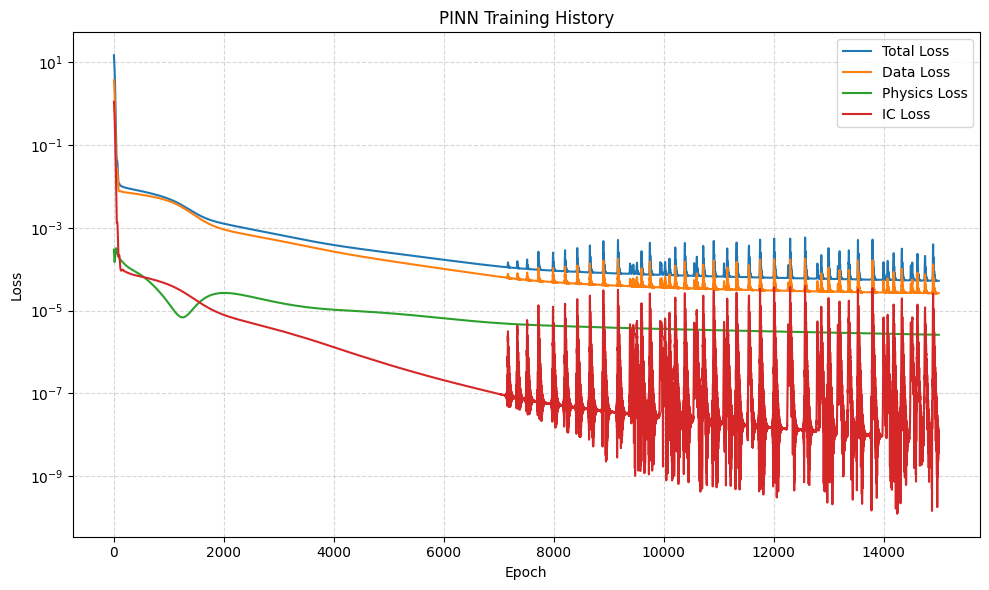

In [ ]:
plt.figure(figsize=(10, 6))
plt.semilogy(loss_history, label="Total Loss")
plt.semilogy(data_loss_history, label="Data Loss")
plt.semilogy(physics_loss_history, label="Physics Loss")
plt.semilogy(ic_loss_history, label="IC Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("PINN Training History")
plt.grid(True, ls="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

**A word on IC LOSS:**
The IC loss shows rapid oscillations. Since the absolute magnitude of the IC loss is the smallest among all objectives, even minor adjustments cause noticeable spikes in its value.
This behavior is expected,considering tug of war between three losses. Nothing to worry about. The network successfully keeps the initial condition intact in all final predictions.

## Arrhenius Law Test

The network independently learns \(k\) and \(b\) at each temperature, and we examine whether the learned parameters follow Arrhenius behaviour. They should !

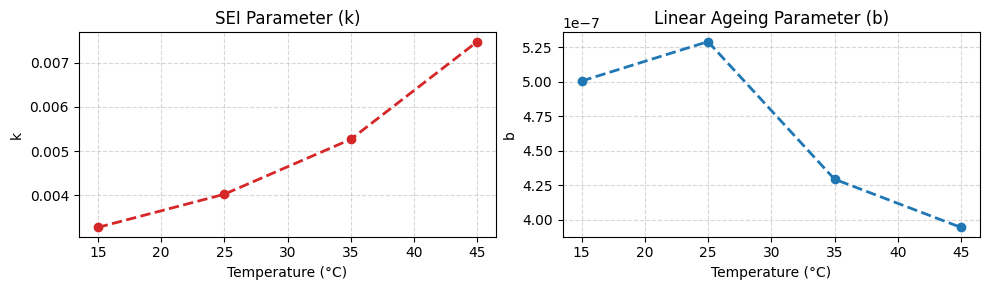

In [ ]:
temps = [15, 25, 35, 45]

fig, ax = plt.subplots(1, 2, figsize=(10, 3))

for a, y, title, color in zip(
    ax,
    [k_final, b_final],
    ["SEI Parameter (k)", "Linear Ageing Parameter (b)"],
    ["tab:red", "tab:blue"]
):
    a.plot(temps, y, 'o--', lw=2, color=color)
    a.set_title(title)
    a.set_xlabel("Temperature (°C)")
    a.grid(True, ls='--', alpha=0.5)

ax[0].set_ylabel("k")
ax[1].set_ylabel("b")

plt.tight_layout()
plt.show()

<h3>Physics Parameter Inference</h3>

<div style="font-size: 16px;
border-left: 5px solid #2e86de;
padding: 12px 18px;
background-color: #f8f9fa;
border-radius: 4px;
">


A quick inspection of the discovered parameters already suggests that the PINN has identified physically meaningful degradation behaviour.

The SEI-growth parameter **\(k\)** increases monotonically with temperature, indicating accelerated degradation kinetics at elevated temperatures. This trend aligns with the well-established understanding that higher temperatures promote electrochemical side reactions and faster SEI-layer growth.

In contrast, the calendar-aging parameter **\(b\)** remains several orders of magnitude smaller than the SEI contribution, suggesting that the degradation is dominated primarily by diffusion-limited SEI formation, with only a minor contribution from long-term calendar aging mechanism.


##**Physics Parameter Inference**

<div style="font-size: 16px;
border-left: 5px solid #2e86de;
padding: 12px 18px;
background-color: #f8f9fa;
border-radius: 4px;
">


Arrhenius relationship:

$$
k = A \exp\left(-\frac{E_a}{RT}\right)
$$

Taking the natural logarithm gives:

$$
\ln(k) = \ln(A) - \frac{E_a}{R}\left(\frac{1}{T}\right)
$$


Therefore, a linear relationship between **ln(k)** and **1/T** is expected.

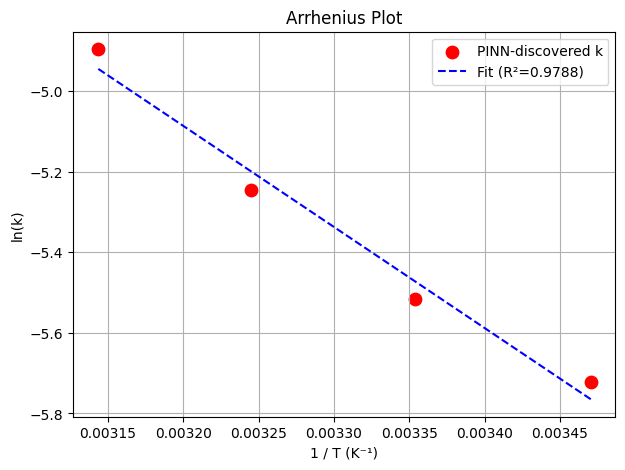

In [ ]:
# Temperatures (°C)
T_C = np.array([15, 25, 35, 45])

# Convert to Kelvin
T_K = T_C + 273.15

# Arrhenius variables (using k_final directly since it is already a numpy array)
x = 1 / T_K
y = np.log(k_final)

# Linear regression
slope, intercept = np.polyfit(x, y, 1)

# Predicted line
y_fit = slope * x + intercept

# R²
ss_res = np.sum((y - y_fit)**2)
ss_tot = np.sum((y - np.mean(y))**2)
r2 = 1 - ss_res / ss_tot

# Plot
plt.figure(figsize=(7,5))
plt.scatter(x, y, color='red', s=80, label='PINN-discovered k')
plt.plot(x, y_fit, 'b--', label=f'Fit (R²={r2:.4f})')
plt.xlabel('1 / T (K⁻¹)')
plt.ylabel('ln(k)')
plt.title('Arrhenius Plot')
plt.grid(True)
plt.legend()
plt.show()

R = 8.314  # J/mol-K
Ea = -slope * R

display(HTML(f"""
<div style="font-size:18px; font-weight:bold; color:darkblue;">
    Activation Energy = {Ea/1000:.2f} kJ/mol<br>
    Arrhenius Fit R² = {r2:.4f}
</div>
"""))

<h3>Conclusion</h3>

<div style="font-size: 16px;
border-left: 5px solid #2e86de;
padding: 12px 18px;
background-color: #f8f9fa;
border-radius: 4px;
">

The discovered **SEI-growth parameter** showed a clear temperature dependence and exhibited a strong Arrhenius relationship (**R² ≈ 0.98**).


#**Forecasting**

I have additional data for **900 days** of capacity loss at **20°C** and **60°C**.
Let's train the PINN using data up to **500 days** and forecast the remaining duration.

In [ ]:
time_days_full = [0,100,200,300,400,500,600,700,800,900]

loss_20C = [0.000,0.038,0.054,0.067,0.078,0.089,0.096,0.103,0.107,0.110]


loss_60C = [0.000,0.093,0.120,0.145,0.167, 0.183,0.198,0.208,0.217,0.226]



q_20C = to_q_tensor(loss_20C)
q_60C = to_q_tensor(loss_60C)

In [ ]:
#============================================================
# Training Dataset
# ============================================================

time_days_train = [0,100,200,300,400,500]

t_data = torch.tensor(
    time_days_train,
    dtype=torch.float32
).unsqueeze(1)

q_20_train = q_20C[:6]

q_60_train = q_60C[:6]

datasets = {
    "20°C": q_20_train,
    "60°C": q_60_train
}

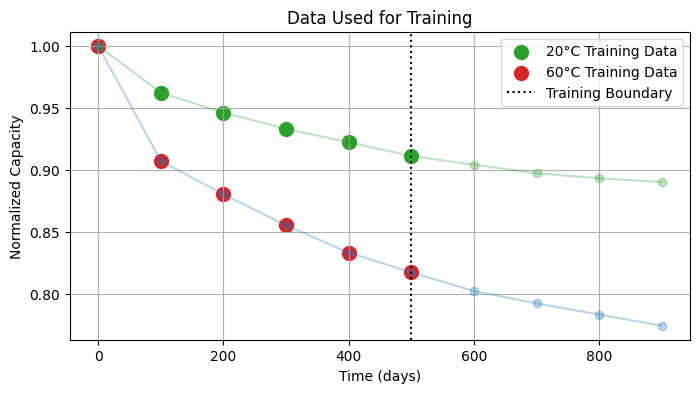

In [ ]:
# ============================================================
# Training Data Visualization
# ============================================================

plt.figure(figsize=(8,4))

plt.plot(time_days_full,
         q_20C.numpy().flatten(),
         "o-",
         color="tab:green",
         alpha=0.3)

plt.plot(time_days_full,
         q_60C.numpy().flatten(),
         "o-",
         color="tab:blue",
         alpha=0.3)

plt.scatter(
    time_days_train,
    q_20_train.numpy().flatten(),
    s=100,
    color="tab:green",
    label="20°C Training Data"
)

plt.scatter(
    time_days_train,
    q_60_train.numpy().flatten(),
    s=100,
    color="tab:red",
    label="60°C Training Data"
)

plt.axvline(
    500,
    linestyle=":",
    color="black",
    label="Training Boundary"
)

plt.xlabel("Time (days)")
plt.ylabel("Normalized Capacity")
plt.title("Data Used for Training")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# ============================================================
# PINN Architecture
# ============================================================

class BatteryPINN(nn.Module):

    def __init__(self):

        super().__init__()

        self.t_max = 900.0

        self.net = nn.Sequential(
            nn.Linear(1,32), nn.Tanh(),
            nn.Linear(32,32), nn.Tanh(),
            nn.Linear(32,1)
        )

        self.k_raw = nn.Parameter(torch.tensor(-5.3))
        self.b_raw = nn.Parameter(torch.tensor(-9.0))

    @property
    def k(self):
        return F.softplus(self.k_raw)

    @property
    def b(self):
        return F.softplus(self.b_raw)

    def forward(self,t):
        return self.net(t/self.t_max)

We will use the same Diffusion Limited SEI Growth Equation in the loss function.

And for forecasting,

$$
\lambda_{\text{Data}} = 1,
\qquad
\lambda_{\text{Physics}} = 1,
\qquad
\lambda_{\text{IC}} = 1
$$

give the best results.

In [ ]:
# ============================================================
# PINN Loss Function
# ============================================================

def pinn_loss(model,
              t_data,
              q_true,
              t_phys,
              lambda_data=1,
              lambda_phys=1,
              lambda_ic=1):

    mse = nn.MSELoss()

    loss_data = mse(
        model(t_data),
        q_true
    )

    q_phys = model(t_phys)

    dQ_dt = torch.autograd.grad(
        q_phys,
        t_phys,
        grad_outputs=torch.ones_like(q_phys),
        create_graph=True
    )[0]

    sqrt_t = torch.sqrt(t_phys)

    residual = (
        sqrt_t*dQ_dt
        + model.k
        + model.b*sqrt_t
    )

    loss_phys = torch.mean(residual**2)

    t0 = torch.zeros((1,1))

    loss_ic = mse(
        model(t0),
        torch.ones((1,1))
    )

    loss_total = (
        lambda_data*loss_data
        + lambda_phys*loss_phys
        + lambda_ic*loss_ic
    )

    return (
        loss_total,
        loss_data,
        loss_phys,
        loss_ic
    )

In [ ]:
datasets = {
    "20°C": q_20_train,
    "60°C": q_60_train
}

In [ ]:
# ============================================================
# Model Setup and Training
# ============================================================
results = {}

for temp, q_train in datasets.items():

    print(f"\nTraining PINN for {temp}")

    model = BatteryPINN()

    # Physics collocation points
    t_phys = torch.linspace(
        0.1, 900.0, 50
    ).unsqueeze(1).requires_grad_(True)

    # Independent learning rates
    optimizer = torch.optim.Adam([
        {"params": model.net.parameters(), "lr": 1e-3},
        {"params": [model.k_raw, model.b_raw], "lr": 3e-3}
    ])

    # History
    loss_history = []
    data_loss_history = []
    physics_loss_history = []
    ic_loss_history = []

    epochs = 20000

    for epoch in range(epochs + 1):

        model.train()
        optimizer.zero_grad()

        total_loss, data_loss, physics_loss, ic_loss = pinn_loss(
            model,
            t_data,
            q_train,
            t_phys,
            lambda_data=1,
            lambda_phys=1,
            lambda_ic=1
        )

        total_loss.backward()
        optimizer.step()

        loss_history.append(total_loss.item())
        data_loss_history.append(data_loss.item())
        physics_loss_history.append(physics_loss.item())
        ic_loss_history.append(ic_loss.item())

        if epoch % 5000 == 0:

            print(
                f"Epoch {epoch:05d} | "
                f"Total: {total_loss.item():.6e} | "
                f"Data: {data_loss.item():.6e} | "
                f"Physics: {physics_loss.item():.6e} | "
                f"IC: {ic_loss.item():.6e}"
            )

            print(
                f"k = {model.k.item():.7f} | "
                f"b = {model.b.item():.7f}"
            )

    # Store discovered parameters
    results[temp] = {
        "model": model,
        "k": model.k.item(),
        "b": model.b.item(),
        "loss_history": loss_history,
        "data_loss_history": data_loss_history,
        "physics_loss_history": physics_loss_history,
        "ic_loss_history": ic_loss_history
    }


Training PINN for 20°C
Epoch 00000 | Total: 1.611700e+00 | Data: 7.993106e-01 | Physics: 1.645887e-05 | IC: 8.123726e-01
k = 0.0049643 | b = 0.0001230
Epoch 05000 | Total: 1.318402e-05 | Data: 1.199460e-05 | Physics: 6.594203e-07 | IC: 5.300002e-07
k = 0.0010026 | b = 0.0000301
Epoch 10000 | Total: 1.381052e-06 | Data: 7.827712e-07 | Physics: 2.524675e-07 | IC: 3.458139e-07
k = 0.0008145 | b = 0.0000973
Epoch 15000 | Total: 3.270627e-07 | Data: 1.639904e-07 | Physics: 1.548750e-07 | IC: 8.197393e-09
k = 0.0010628 | b = 0.0000772
Epoch 20000 | Total: 2.085714e-07 | Data: 1.009857e-07 | Physics: 1.055012e-07 | IC: 2.084576e-09
k = 0.0012980 | b = 0.0000580

Training PINN for 60°C
Epoch 00000 | Total: 1.369410e+00 | Data: 5.952663e-01 | Physics: 5.082800e-05 | IC: 7.740932e-01
k = 0.0049643 | b = 0.0001230
Epoch 05000 | Total: 1.616078e-05 | Data: 1.491040e-05 | Physics: 1.175044e-06 | IC: 7.533893e-08
k = 0.0031725 | b = 0.0000100
Epoch 10000 | Total: 1.886856e-06 | Data: 1.362459e-06 |

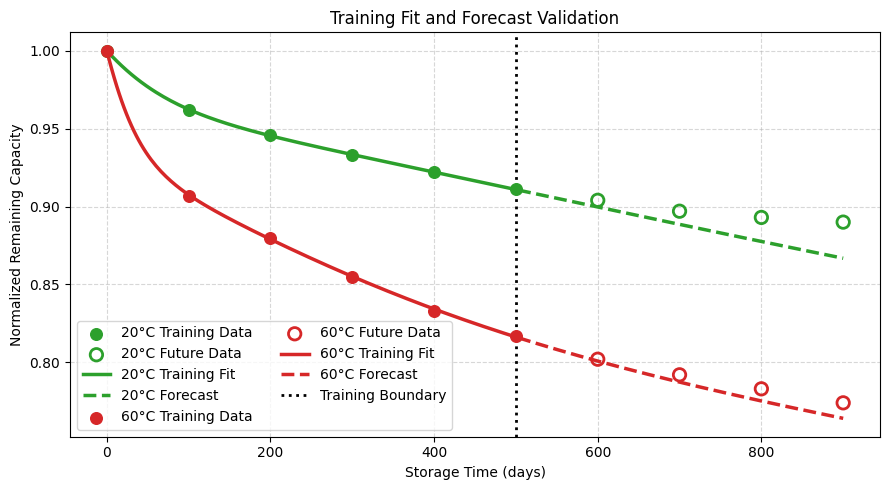

In [ ]:
# ============================================================
# Forecast Validation
# ============================================================
t_plot = torch.linspace(0, 900, 300).unsqueeze(1)

time_days_train = [0, 100, 200, 300, 400, 500]

full_data = {
    "20°C": q_20C,
    "60°C": q_60C
}

colors = ["tab:green", "tab:red"]

plt.figure(figsize=(9,5))

for (temp, q_full), color in zip(
    full_data.items(),
    colors
):
    model = results[temp]["model"]

    with torch.no_grad():
        q_pred = model(t_plot).cpu().numpy().flatten()

    t_pred = t_plot.cpu().numpy().flatten()

    train_mask = t_pred <= 500
    forecast_mask = t_pred >= 500

    q_full_np = q_full.numpy().flatten()

    # Training points (solid filled circles, first 6 elements: 0 to 500 days)
    plt.scatter(
        time_days_full[:6],
        q_full_np[:6],
        color=color,
        s=70,
        zorder=5,
        label=f"{temp} Training Data"
    )

    # Future points on dotted line (completely hollow circles, remaining elements: 600 to 900 days)
    plt.scatter(
        time_days_full[6:],
        q_full_np[6:],
        facecolors="none",
        edgecolors=color,
        s=80,
        linewidths=2,
        zorder=5,
        label=f"{temp} Future Data"
    )

    # Fit region
    plt.plot(
        t_pred[train_mask],
        q_pred[train_mask],
        color=color,
        lw=2.5,
        label=f"{temp} Training Fit"
    )

    # Forecast region (dotted line)
    plt.plot(
        t_pred[forecast_mask],
        q_pred[forecast_mask],
        "--",
        color=color,
        lw=2.5,
        label=f"{temp} Forecast"
    )

plt.axvline(
    500,
    color="black",
    linestyle=":",
    linewidth=2,
    label="Training Boundary"
)

plt.xlabel("Storage Time (days)")
plt.ylabel("Normalized Remaining Capacity")
plt.title("Training Fit and Forecast Validation")
plt.grid(True, ls="--", alpha=0.5)
plt.legend(ncol=2)
plt.tight_layout()
plt.show()

### **Forecasting Performance**


Notice the forecast for the **60°C** data is better than for the **20°C** data.

> **The efficacy of a PINN heavily depends on how well the governing physical equations models that mechanism.**

Here, we used the **Diffusion Limited SEI Growth Equation** as our physics regularizer. Since SEI growth is a thermally activated process, it becomes prominent at higher temperatures. This equation represents the dominant degradation well at higher temperatures, so the PINN makes forecasts at **60°** with better accuracy.

At lower temperatures like **20°C**, the rate of SEI growth is much slower. The training data is more susceptible to secondary degradation mechanisms not fully captured by the single-equation physical model.

